# SD-210 Network Rollout Analysis
**Sprint 3 — synthetic-data operations analytics**
**Decision question:** With limited capital, which site upgrades look most promising for improving network quality and reducing avoidable subscriber churn?
The analysis compares fictional site conditions and intervention assumptions. Results are not an engineering or investment recommendation.



## 1. Load the synthetic data



In [94]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "__file__" in globals():
    PROJECT_DIR = Path(__file__).resolve().parent.parent
elif Path.cwd().name == "Notebook2":
    PROJECT_DIR = Path.cwd().parent
else:
    PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR.parent / "legacy" / "Sprint3" / "analysis_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)



In [95]:
cell_sites = pd.read_csv(DATA_DIR / 'CellSites.csv')
coverage_grids = pd.read_csv(DATA_DIR / 'CoverageGrids.csv')
subscriber_density = pd.read_csv(DATA_DIR / 'SubscriberDensity.csv')
qoe_measurements = pd.read_csv(DATA_DIR / 'QoEMeasurements.csv')
traffic_loads = pd.read_csv(DATA_DIR / 'TrafficLoads.csv')
capex_projects = pd.read_csv(DATA_DIR / 'CapexProjects.csv')
rollout_milestones = pd.read_csv(DATA_DIR / 'RolloutMilestones.csv')



In [96]:
regions = (coverage_grids[['region_id', 'region_name', 'market_type']]
           .drop_duplicates()
           .merge(cell_sites[['region_id', 'annual_demand_growth', 'gross_margin']].drop_duplicates(subset=['region_id']), on='region_id'))
sites = (cell_sites[['cell_site_id', 'region_id', 'site_name', 'capacity_gbps']]
         .rename(columns={'cell_site_id': 'site_id'})
         .merge(qoe_measurements[['cell_site_id', 'monthly_outage_hours']],
                left_on='site_id', right_on='cell_site_id')
         .drop(columns='cell_site_id'))



In [97]:
subscribers = subscriber_density.rename(columns={'cell_site_id': 'site_id'})
forecast = traffic_loads.rename(columns={'cell_site_id': 'site_id', 'forecast_year': 'year'})
options = capex_projects.rename(columns={
    'capex_project_id': 'option_id', 'cell_site_id': 'site_id', 'project_type': 'upgrade_type'
})
print('Loaded seven exported menu tables:', len(cell_sites), 'cell sites and', len(rollout_milestones), 'milestones')



Loaded seven exported menu tables: 12 cell sites and 72 milestones


## Calibration process: World Bank Data360 Speed Test
I checked the World Bank [Data360 Speed Test dataset (`OOKLA_ST`)](https://data360.worldbank.org/en/dataset/OOKLA_ST) and its public metadata. It covers 2019–2024 and lists 244 economies. The public CSV export contains two annual indicators: `OOKLA_ST_MOB_PER` (Average Download Speed - Mobile Technologies) and `OOKLA_ST_FIX_PER` (Average Download Speed - Fixed Technologies).
A compact summary of the source provides context only; it is not a source of synthetic site records and does not change the model values.



### Summarize and compare with synthetic values
The reference file summarizes each year across the metadata-listed economies; non-missing counts vary. The comparison keeps source and model units separate.



In [98]:
calibration_path = PROJECT_DIR / 'reference_data' / 'ookla_data360_annual_summary.csv'
calibration_summary = pd.read_csv(calibration_path)
assert len(calibration_summary) == 12
assert set(calibration_summary['indicator_code']) == {'OOKLA_ST_MOB_PER', 'OOKLA_ST_FIX_PER'}



In [99]:
reference_2024 = calibration_summary.loc[calibration_summary['year'] == 2024,
    ['indicator', 'observed_economies', 'unit', 'p10', 'median', 'p90']]
synthetic_comparison = pd.DataFrame([
    ('Synthetic baseline download proxy', len(qoe_measurements), 'Mbps',
     qoe_measurements['download_mbps'].quantile(0.10),
     qoe_measurements['download_mbps'].median(),
     qoe_measurements['download_mbps'].quantile(0.90)),
    ('Synthetic baseline QoE score', len(qoe_measurements), '0-100 index',
     qoe_measurements['baseline_qoe_score'].quantile(0.10),
     qoe_measurements['baseline_qoe_score'].median(),
     qoe_measurements['baseline_qoe_score'].quantile(0.90)),
    ('Synthetic site-year peak demand', len(traffic_loads), 'Gbps',
     traffic_loads['peak_demand_gbps'].quantile(0.10),
     traffic_loads['peak_demand_gbps'].median(),
     traffic_loads['peak_demand_gbps'].quantile(0.90)),
], columns=['measure', 'observations', 'unit', 'p10', 'median', 'p90'])
print('Data360 2024 economy summaries (source-reported units):')
print(reference_2024.to_string(index=False))
print('\nSynthetic model summaries:')
print(synthetic_comparison.round(2).to_string(index=False))



Data360 2024 economy summaries (source-reported units):
                                   indicator  observed_economies                unit    p10  median     p90
 Average Download Speed - Fixed Technologies                 243 Kilobits per second 28.121  89.731 242.483
Average Download Speed - Mobile Technologies                 240 Kilobits per second 23.425  55.004 173.401

Synthetic model summaries:
                          measure  observations        unit     p10  median     p90
Synthetic baseline download proxy            12        Mbps 1883.19 3110.40 4037.38
     Synthetic baseline QoE score            12 0-100 index   79.00   85.61   94.46
  Synthetic site-year peak demand            48        Gbps    1.91    3.32    4.67


### Calibration decision and limitations
Both published country-level median series rise between 2019 and 2024, but these are annual economy averages, not site measurements or peak loads. The checked-in summary reports the unit as kilobits per second. The D3a review noted that the longer fixed/mobile descriptions appeared swapped relative to the indicator codes, but this could not be independently verified from official metadata during this revision. I preserve the source-reported values and labels without conversion; neither the generator's synthetic download proxy nor traffic and QoE assumptions are calibrated from them.
Speedtest users and devices self-select into testing, so the observations are not a census of subscribers or traffic. Annual economy summaries hide provider, technology, and urban/rural differences; observed economy counts are below 244 in some years. Treat these values as broad context, not a universal benchmark or causal estimate.



## 2. Check the seven menu tables
The tables link sites to coverage, subscribers, baseline QoE, four years of traffic, investment choices, and rollout milestones. The model uses one row per site for coverage, subscriber context, and baseline QoE.



In [100]:
assert len([cell_sites, coverage_grids, subscriber_density, qoe_measurements,
            traffic_loads, capex_projects, rollout_milestones]) == 7
assert cell_sites['cell_site_id'].is_unique
assert set(coverage_grids['cell_site_id']) == set(cell_sites['cell_site_id'])
assert set(subscriber_density['coverage_grid_id']) == set(coverage_grids['coverage_grid_id'])
assert set(qoe_measurements['cell_site_id']) == set(cell_sites['cell_site_id'])
assert set(subscribers['site_id']) == set(sites['site_id'])
assert set(options['site_id']) == set(sites['site_id'])
assert set(forecast['year']) == {0, 1, 2, 3}
assert options.groupby('site_id').size().eq(3).all()
assert set(rollout_milestones['capex_project_id']).issubset(set(capex_projects['capex_project_id']))
assert (options.loc[options['upgrade_type'] == 'no_action', 'capex_usd'] == 0).all()
print('Seven menu tables, links, forecast coverage, and three choices per site check out.')



Seven menu tables, links, forecast coverage, and three choices per site check out.


## 3. Define scenarios and QoE
Each scenario changes the realized share of forecast demand growth and sets a capex ceiling. QoE is a visible 0–100 proxy based on capacity utilization and monthly outages.



In [101]:
scenarios = pd.DataFrame([
    ('Conservative', 0.8, 450000, 1.15, 0.8),
    ('Base', 1.0, 750000, 1.00, 1.0),
    ('Growth', 1.2, 1050000, 0.95, 1.1),
], columns=['scenario', 'demand_increase_factor', 'capex_budget_usd', 'capex_factor', 'churn_sensitivity'])

def qoe_score(demand_gbps, capacity_gbps, outage_hours):
    utilization = demand_gbps / capacity_gbps
    score = 100 - 50 * np.maximum(utilization - 0.65, 0) - 2.5 * outage_hours
    return np.clip(score, 35, 100)

scenarios



,scenario,demand_increase_factor,capex_budget_usd,capex_factor,churn_sensitivity
0,Conservative,0.8,450000,1.15,0.8
1,Base,1.0,750000,1.00,1.0
2,Growth,1.2,1050000,0.95,1.1


## 4. Estimate year-three site outcomes
Each investment is compared with no action at the same site. QoE improvement lowers the churn-risk proxy and produces an estimated annual value; this is directional, not causal.



In [102]:
base_demand = forecast.loc[forecast['year'] == 0, ['site_id', 'peak_demand_gbps']].rename(
    columns={'peak_demand_gbps': 'year0_demand_gbps'})
year3_demand = forecast.loc[forecast['year'] == 3, ['site_id', 'peak_demand_gbps']].rename(
    columns={'peak_demand_gbps': 'year3_forecast_gbps'})
site_inputs = (sites.merge(regions, on='region_id')
               .merge(subscribers, on='site_id')
               .merge(base_demand, on='site_id')
               .merge(year3_demand, on='site_id'))



In [103]:
def add_qoe_estimates(candidates):
    candidates['baseline_qoe'] = qoe_score(
        candidates['scenario_demand_gbps'], candidates['capacity_gbps'], candidates['monthly_outage_hours'])
    candidates['upgrade_qoe'] = qoe_score(
        candidates['scenario_demand_gbps'],
        candidates['capacity_gbps'] * candidates['capacity_multiplier'],
        candidates['monthly_outage_hours'] * candidates['outage_multiplier'])
    candidates['qoe_improvement'] = candidates['upgrade_qoe'] - candidates['baseline_qoe']
    return candidates



In [104]:
def add_value_estimates(candidates, scenario_row):
    baseline_churn = 0.0035 + np.maximum(85 - candidates['baseline_qoe'], 0) * 0.0003
    upgrade_churn = 0.0035 + np.maximum(85 - candidates['upgrade_qoe'], 0) * 0.0003
    candidates['monthly_churn_reduction'] = np.maximum(
        baseline_churn - upgrade_churn, 0) * scenario_row['churn_sensitivity']
    candidates['monthly_churn_reduction'] = np.minimum(
        candidates['monthly_churn_reduction'], baseline_churn)
    candidates['benefiting_subscribers'] = np.where(
        candidates['qoe_improvement'] > 0, candidates['subscriber_count'], 0)
    candidates['annual_avoided_churn'] = (
        candidates['subscriber_count'] * candidates['at_risk_share']
        * candidates['monthly_churn_reduction'] * 12)
    candidates['annual_value_usd'] = (
        candidates['annual_avoided_churn'] * candidates['monthly_arpu_usd']
        * candidates['gross_margin'] * 12)
    monthly_value = candidates['annual_value_usd'] / 12
    candidates['payback_months'] = np.where(
        (candidates['capex_usd'] > 0) & (monthly_value > 0),
        candidates['capex_usd'] / monthly_value, np.nan)
    candidates['value_per_capex'] = np.where(
        candidates['capex_usd'] > 0, candidates['annual_value_usd'] / candidates['capex_usd'], 0)
    return candidates



In [105]:
def evaluate_scenario(scenario_row):
    scenario = scenario_row['scenario']
    demand = site_inputs.copy()
    forecast_increase = demand['year3_forecast_gbps'] - demand['year0_demand_gbps']
    demand['scenario_demand_gbps'] = demand['year0_demand_gbps'] + forecast_increase * scenario_row['demand_increase_factor']
    candidates = options.merge(demand, on='site_id')
    candidates['scenario'] = scenario
    candidates['capex_usd'] = candidates['capex_usd'] * scenario_row['capex_factor']
    candidates = add_qoe_estimates(candidates)
    return add_value_estimates(candidates, scenario_row)



In [106]:
results = pd.concat([evaluate_scenario(row) for _, row in scenarios.iterrows()], ignore_index=True)
results[['scenario', 'site_id', 'upgrade_type', 'capex_usd', 'qoe_improvement',
         'benefiting_subscribers', 'annual_avoided_churn', 'annual_value_usd', 'payback_months']].head(9)



,scenario,site_id,upgrade_type,capex_usd,qoe_improvement,benefiting_subscribers,annual_avoided_churn,annual_value_usd,payback_months
0,Conservative,SITE-001,no_action,0.00,0.000000,0,0.000000,0.000000,NaN
1,Conservative,SITE-001,capacity_expansion,147398.95,0.030000,8344,0.000000,0.000000,NaN
2,Conservative,SITE-001,targeted_densification,167448.05,0.082500,8344,0.000000,0.000000,NaN
3,Conservative,SITE-002,no_action,0.00,0.000000,0,0.000000,0.000000,NaN
4,Conservative,SITE-002,capacity_expansion,102744.45,16.737856,5905,68.518094,41174.324780,29.944229
5,Conservative,SITE-002,targeted_densification,272754.70,22.886533,5905,69.067133,41504.256924,78.860740
6,Conservative,SITE-003,no_action,0.00,0.000000,0,0.000000,0.000000,NaN
7,Conservative,SITE-003,capacity_expansion,156949.70,15.536038,4010,29.239359,17705.986627,106.370599
8,Conservative,SITE-003,targeted_densification,273312.45,20.859458,4010,29.239359,17705.986627,185.233925


## 5. Rank investments within each budget
A greedy ranking selects the best modeled annual value per capex dollar that fits the budget, with at most one upgrade per site. It is not a global optimization.



In [107]:
def rank_scenario(scenario_row):
    ranked = results.loc[
        (results['scenario'] == scenario_row['scenario']) & (results['capex_usd'] > 0)
    ].copy()
    ranked = ranked.sort_values(
        ['value_per_capex', 'qoe_improvement'], ascending=False
    ).reset_index(drop=True)
    ranked['investment_rank'] = np.arange(1, len(ranked) + 1)
    ranked['selected'] = False
    remaining_budget = scenario_row['capex_budget_usd']
    used_sites = set()
    selected_indexes = []
    for index, candidate in ranked.iterrows():
        if candidate['site_id'] not in used_sites and candidate['capex_usd'] <= remaining_budget:
            selected_indexes.append(index)
            used_sites.add(candidate['site_id'])
            remaining_budget -= candidate['capex_usd']
    ranked.loc[selected_indexes, 'selected'] = True
    ranked['capex_budget_usd'] = scenario_row['capex_budget_usd']
    return ranked



In [108]:
ranking_parts = []
selected_parts = []
for _, scenario_row in scenarios.iterrows():
    ranked = rank_scenario(scenario_row)
    ranking_parts.append(ranked)
    selected_parts.append(ranked.loc[ranked['selected']])

investment_ranking = pd.concat(ranking_parts, ignore_index=True)
portfolio = pd.concat(selected_parts, ignore_index=True)



In [109]:
scenario_summary = (portfolio.groupby('scenario', as_index=False)
                    .agg(selected_projects=('option_id', 'count'),
                         capex_spend_usd=('capex_usd', 'sum'),
                         annual_avoided_churn=('annual_avoided_churn', 'sum'),
                         annual_value_usd=('annual_value_usd', 'sum'),
                         average_qoe_improvement=('qoe_improvement', 'mean')))
scenario_summary = scenarios[['scenario', 'capex_budget_usd']].merge(scenario_summary, on='scenario', how='left').fillna(0)
scenario_summary['unused_budget_usd'] = scenario_summary['capex_budget_usd'] - scenario_summary['capex_spend_usd']
scenario_summary



,scenario,capex_budget_usd,selected_projects,capex_spend_usd,annual_avoided_churn,annual_value_usd,average_qoe_improvement,unused_budget_usd
0,Conservative,450000,4,434757.50,264.179030,141144.654682,15.770661,15242.50
1,Base,750000,7,719301.00,487.001835,255137.724390,15.731864,30699.00
2,Growth,1050000,10,1039409.25,649.321532,340927.862099,15.383009,10590.75


## 6. Check edge cases and portfolio constraints
No-action has zero spend and undefined payback. The deliberately low-risk first site should receive little benefit; each portfolio must stay within its budget and choose at most one upgrade per site.



In [110]:
no_action = results.loc[results['upgrade_type'] == 'no_action']
assert (no_action['capex_usd'] == 0).all()
assert no_action['payback_months'].isna().all()
low_risk = results.loc[(results['site_id'] == 'SITE-001') & (results['upgrade_type'] == 'capacity_expansion')]
assert low_risk['qoe_improvement'].max() < 0.5
for _, scenario_row in scenarios.iterrows():
    chosen = portfolio.loc[portfolio['scenario'] == scenario_row['scenario']]
    assert chosen['site_id'].is_unique
    assert chosen['capex_usd'].sum() <= scenario_row['capex_budget_usd']
assert (results['qoe_improvement'] >= -1e-9).all()
print('Edge cases and budget/one-option-per-site checks passed.')



Edge cases and budget/one-option-per-site checks passed.


## 7. Compare the scenario results
The following summaries show portfolio spend, selected options, and modeled outcomes.



### Compare portfolio spend and candidates



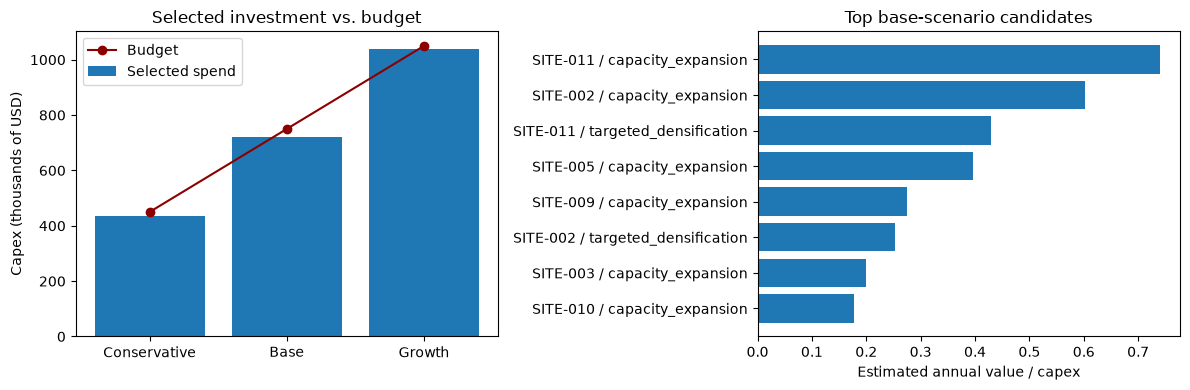

In [111]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(scenario_summary['scenario'], scenario_summary['capex_spend_usd'] / 1000, label='Selected spend')
axes[0].plot(scenario_summary['scenario'], scenario_summary['capex_budget_usd'] / 1000,
             color='darkred', marker='o', label='Budget')
axes[0].set_ylabel('Capex (thousands of USD)')
axes[0].set_title('Selected investment vs. budget')
axes[0].legend()

base_ranked = investment_ranking.loc[investment_ranking['scenario'] == 'Base'].head(8)
axes[1].barh(base_ranked['site_id'] + ' / ' + base_ranked['upgrade_type'], base_ranked['value_per_capex'])
axes[1].invert_yaxis()
axes[1].set_xlabel('Estimated annual value / capex')
axes[1].set_title('Top base-scenario candidates')
plt.tight_layout()
plt.show()



### Export scenario results



In [112]:
results.to_csv(OUTPUT_DIR / 'scenario_results.csv', index=False)
investment_ranking.to_csv(OUTPUT_DIR / 'investment_ranking.csv', index=False)
scenario_summary.to_csv(OUTPUT_DIR / 'scenario_summary.csv', index=False)



### Review the Base scenario



In [113]:
base_summary = scenario_summary.loc[scenario_summary['scenario'] == 'Base'].iloc[0]
base_choices = portfolio.loc[portfolio['scenario'] == 'Base', ['site_id', 'upgrade_type']]
print('Base scenario selected', int(base_summary['selected_projects']), 'projects for $',
      round(base_summary['capex_spend_usd']), 'of $', round(base_summary['capex_budget_usd']), 'budget.')
print('Selected options:', base_choices.to_dict('records'))
print('Scenario summaries, option rankings, and site outcomes are ready.')



Base scenario selected 7 projects for $ 719301 of $ 750000 budget.
Selected options: [{'site_id': 'SITE-011', 'upgrade_type': 'capacity_expansion'}, {'site_id': 'SITE-002', 'upgrade_type': 'capacity_expansion'}, {'site_id': 'SITE-005', 'upgrade_type': 'capacity_expansion'}, {'site_id': 'SITE-009', 'upgrade_type': 'capacity_expansion'}, {'site_id': 'SITE-003', 'upgrade_type': 'capacity_expansion'}, {'site_id': 'SITE-010', 'upgrade_type': 'capacity_expansion'}, {'site_id': 'SITE-004', 'upgrade_type': 'capacity_expansion'}]
Scenario summaries, option rankings, and site outcomes are ready.
